In [3]:
import xarray as xr
from pathlib import Path

file_path = Path(r"C:\Users\Mkosh\OneDrive\Desktop\Project\AgriRain-ML\data\raw\rainfall\RF25_ind2024_rfp25.nc")
print("File Exists:",file_path.exists())

File Exists: True


In [4]:
ds=xr.open_dataset(file_path)
ds

<xarray.Dataset> Size: 26MB
Dimensions:    (TIME: 366, LATITUDE: 129, LONGITUDE: 135)
Coordinates:
  * TIME       (TIME) datetime64[ns] 3kB 2024-01-01 2024-01-02 ... 2024-12-31
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Data variables:
    RAINFALL   (TIME, LATITUDE, LONGITUDE) float32 25MB ...
Attributes:
    history:      FERRET V6.82    9-Apr-26
    Conventions:  CF-1.0

In [5]:
ds["RAINFALL"].attrs

{'long_name': 'Rainfall', 'units': 'mm', 'history': 'From ind2024_rfp25.grd'}

In [7]:
print("First date:", ds.TIME.values[0])
print("Last date:", ds.TIME.values[-1])

print("Minimum latitude:", ds.LATITUDE.min().values)
print("Maximum latitude:", ds.LATITUDE.max().values)

print("Minimum longitude:", ds.LONGITUDE.min().values)
print("Maximum longitude:", ds.LONGITUDE.max().values)

First date: 2024-01-01T00:00:00.000000000
Last date: 2024-12-31T00:00:00.000000000
Minimum latitude: 6.5
Maximum latitude: 38.5
Minimum longitude: 66.5
Maximum longitude: 100.0


In [8]:
rainfall = ds["RAINFALL"]

print("Total observations:", rainfall.size)
print("Missing values:", rainfall.isnull().sum().values)
print("Minimum rainfall:", rainfall.min().values)
print("Maximum rainfall:", rainfall.max().values)
print("Mean rainfall:", rainfall.mean().values)

Total observations: 6373890
Missing values: 4557066
Minimum rainfall: 0.0
Maximum rainfall: 660.5492
Mean rainfall: 3.320558


In [9]:
total = rainfall.size
missing = rainfall.isnull().sum().values
valid = total - missing

print("Missing percentage:", (missing / total) * 100)
print("Valid percentage:", (valid / total) * 100)

Missing percentage: 71.49583692219352
Valid percentage: 28.50416307780649


In [10]:
missing_map = rainfall.isnull().mean(dim="TIME")

print(missing_map)

<xarray.DataArray 'RAINFALL' (LATITUDE: 129, LONGITUDE: 135)> Size: 139kB
array([[1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       ...,
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.]], shape=(129, 135))
Coordinates:
  * LATITUDE   (LATITUDE) float64 1kB 6.5 6.75 7.0 7.25 ... 38.0 38.25 38.5
  * LONGITUDE  (LONGITUDE) float64 1kB 66.5 66.75 67.0 ... 99.5 99.75 100.0
Attributes:
    long_name:  Rainfall
    units:      mm
    history:    From ind2024_rfp25.grd


In [11]:
import sys

print(sys.executable)

c:\Users\Mkosh\OneDrive\Desktop\Project\AgriRain-ML\.venv\Scripts\python.exe


In [12]:
%pip show matplotlib

Name: matplotlib
Version: 3.11.2
Summary: Python plotting package
Home-page: https://matplotlib.org
Author: John D. Hunter, Michael Droettboom
Author-email: Unknown <matplotlib-users@python.org>
License: License agreement for matplotlib versions 1.3.0 and later

 1. This LICENSE AGREEMENT is between the Matplotlib Development Team
 ("MDT"), and the Individual or Organization ("Licensee") accessing and
 otherwise using matplotlib software in source or binary form and its
 associated documentation.

 2. Subject to the terms and conditions of this License Agreement, MDT
 hereby grants Licensee a nonexclusive, royalty-free, world-wide license
 to reproduce, analyze, test, perform and/or display publicly, prepare
 derivative works, distribute, and otherwise use matplotlib
 alone or in any derivative version, provided, however, that MDT's
 License Agreement and MDT's notice of copyright, i.e., "Copyright (c)
 2012- Matplotlib Development Team; All Rights Reserved" are retained in
 matplotlib

In [16]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp315-cp315-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp315-cp315-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp315-cp315-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl (9.5 MB)
Using cached contourpy-1.4.0-cp315-cp315-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------- ----------------------- 1.0/2.5 MB 4.9 MB/s eta 0:00:01
   ---------------------------- ----------- 1.8/2.5 MB 4.4 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 4.0 MB/s  0:00:00
Using cached kiwi

In [1]:
import matplotlib.pyplot as plt

print("Matplotlib installed successfully!")

Matplotlib installed successfully!


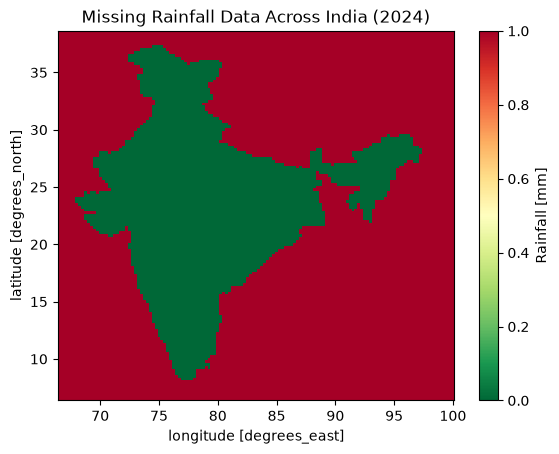

In [13]:
import matplotlib.pyplot as plt

missing_map.plot(
    cmap="RdYlGn_r",
    vmin=0,
    vmax=1
)

plt.title("Missing Rainfall Data Across India (2024)")
plt.show()

In [14]:
print("Grid points with no missing days:",
      (missing_map == 0).sum().values)

print("Grid points with some missing days:",
      ((missing_map > 0) & (missing_map < 1)).sum().values)

print("Grid points with all days missing:",
      (missing_map == 1).sum().values)

Grid points with no missing days: 4964
Grid points with some missing days: 0
Grid points with all days missing: 12451


In [15]:
print("Negative rainfall observations:",
      (rainfall < 0).sum().values)

print("Zero rainfall observations:",
      (rainfall == 0).sum().values)

print("Positive rainfall observations:",
      (rainfall > 0).sum().values)

Negative rainfall observations: 0
Zero rainfall observations: 1294954
Positive rainfall observations: 521870
